# Fase 1 — Análisis Exploratorio de Datos (EDA)
## Sistema de alerta temprana de riesgo materno-perinatal en zonas dispersas y comunidades indígenas

**Proyecto de aula — Inteligencia Artificial (Séptimo semestre)**
**Universidad Popular del Cesar (UPC)**

Este notebook es el segundo entregable de la Fase 1 del proyecto y complementa el documento de propuesta.
Aquí se realiza el análisis exploratorio del conjunto de datos público **Maternal Health Risk Data Set**
(UC Irvine Machine Learning Repository; Ahmed et al., 2020), identificado como una de las fuentes de datos
del proyecto. Este dataset contiene 1014 registros de gestantes con variables clínicas (edad, presión arterial,
glucosa, temperatura corporal y frecuencia cardiaca) y su nivel de riesgo obstétrico asociado. Se usa como base
para validar el enfoque metodológico y como referencia de rangos clínicos plausibles, antes de incorporar en la
Fase 2 los datos simulados de controles prenatales en zonas rurales del Cesar y La Guajira.

**Contenido:**
1. Carga y descripción del dataset
2. Estadísticas descriptivas
3. Visualizaciones
4. Identificación de problemas de calidad de datos (nulos, atípicos, desbalance de clases)
5. Conclusiones del análisis exploratorio


## 0. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)


## 1. Carga y descripción del dataset

El dataset se obtiene en formato CSV con las siguientes siete variables:

| Variable | Descripción | Tipo |
|---|---|---|
| `Age` | Edad de la gestante (años) | Numérica |
| `SystolicBP` | Presión arterial sistólica (mmHg) | Numérica |
| `DiastolicBP` | Presión arterial diastólica (mmHg) | Numérica |
| `BS` | Nivel de glucosa en sangre (mmol/L) | Numérica |
| `BodyTemp` | Temperatura corporal (°F) | Numérica |
| `HeartRate` | Frecuencia cardiaca (lpm) | Numérica |
| `RiskLevel` | Nivel de riesgo obstétrico (low risk / mid risk / high risk) | Categórica (variable objetivo) |


In [2]:
df = pd.read_csv("maternal_health_risk_uci.csv")
print(f"Dimensiones del dataset: {df.shape[0]} registros x {df.shape[1]} variables")
df.head(10)


Dimensiones del dataset: 1014 registros x 7 variables


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.00,98.0,86,high risk
1,35,140,90,13.00,98.0,70,high risk
2,29,90,70,8.00,100.0,80,high risk
3,30,140,85,7.00,98.0,70,high risk
4,35,120,60,6.10,98.0,76,low risk
5,23,140,80,7.01,98.0,70,high risk
6,23,130,70,7.01,98.0,78,mid risk
7,35,85,60,11.00,102.0,86,high risk
8,32,120,90,6.90,98.0,70,mid risk
9,42,130,80,18.00,98.0,70,high risk


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   str    
dtypes: float64(2), int64(4), str(1)
memory usage: 55.6 KB


In [4]:
# Orden natural de las categorías de riesgo, para que los gráficos posteriores respeten esta jerarquía
orden_riesgo = ["low risk", "mid risk", "high risk"]
df["RiskLevel"] = pd.Categorical(df["RiskLevel"], categories=orden_riesgo, ordered=True)
df["RiskLevel"].value_counts().reindex(orden_riesgo)


RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

## 2. Estadísticas descriptivas

Se calculan medidas de tendencia central y dispersión para cada variable numérica, y se comparan
las medias de cada variable clínica según el nivel de riesgo obstétrico.


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,1014.0,29.871795,13.474386,10.0,19.0,26.0,39.0,70.0
SystolicBP,1014.0,113.198225,18.403913,70.0,100.0,120.0,120.0,160.0
DiastolicBP,1014.0,76.460552,13.885796,49.0,65.0,80.0,90.0,100.0
BS,1014.0,8.725986,3.293532,6.0,6.9,7.5,8.0,19.0
BodyTemp,1014.0,98.665089,1.371384,98.0,98.0,98.0,98.0,103.0
HeartRate,1014.0,74.301775,8.088702,7.0,70.0,76.0,80.0,90.0


In [6]:
# Estadísticas descriptivas por nivel de riesgo
df.groupby("RiskLevel", observed=True).agg(["mean", "std", "min", "max"]).round(2)


Age                SystolicBP                 DiastolicBP         \
            mean    std min max       mean    std min  max        mean    std   
RiskLevel                                                                       
low risk   26.87  13.12  10  70     105.87  15.89  70  129       72.53  13.05   
mid risk   28.36  12.55  10  60     113.15  14.98  70  140       74.23  11.49   
high risk  36.22  13.03  12  65     124.19  20.23  83  160       85.07  14.11   

                       BS                  BodyTemp                     \
          min  max   mean   std  min   max     mean   std   min    max   
RiskLevel                                                                
low risk   49  100   7.22  0.65  6.0  11.0    98.37  1.11  98.0  103.0   
mid risk   50  100   7.80  2.29  6.0  18.0    98.83  1.43  98.0  103.0   
high risk  60  100  12.12  4.17  6.1  19.0    98.90  1.56  98.0  103.0   

          HeartRate                
               mean   std min max  
RiskLevel                          
low risk      72.77  8.29   7  88  
mid risk      74.18  6.77  60  88  
high risk     76.74  8.70  60  90

In [7]:
# Asimetría (skewness) y curtosis por variable, útiles para detectar distribuciones no normales
skew_kurt = pd.DataFrame({
    "skewness": df.select_dtypes(include=np.number).skew(),
    "kurtosis": df.select_dtypes(include=np.number).kurt(),
})
skew_kurt.round(2)


,skewness,kurtosis
Age,0.78,-0.39
SystolicBP,-0.25,-0.61
DiastolicBP,-0.05,-0.95
BS,1.87,2.30
BodyTemp,1.75,1.45
HeartRate,-1.04,8.40


## 3. Visualizaciones

### 3.1 Distribución de cada variable clínica

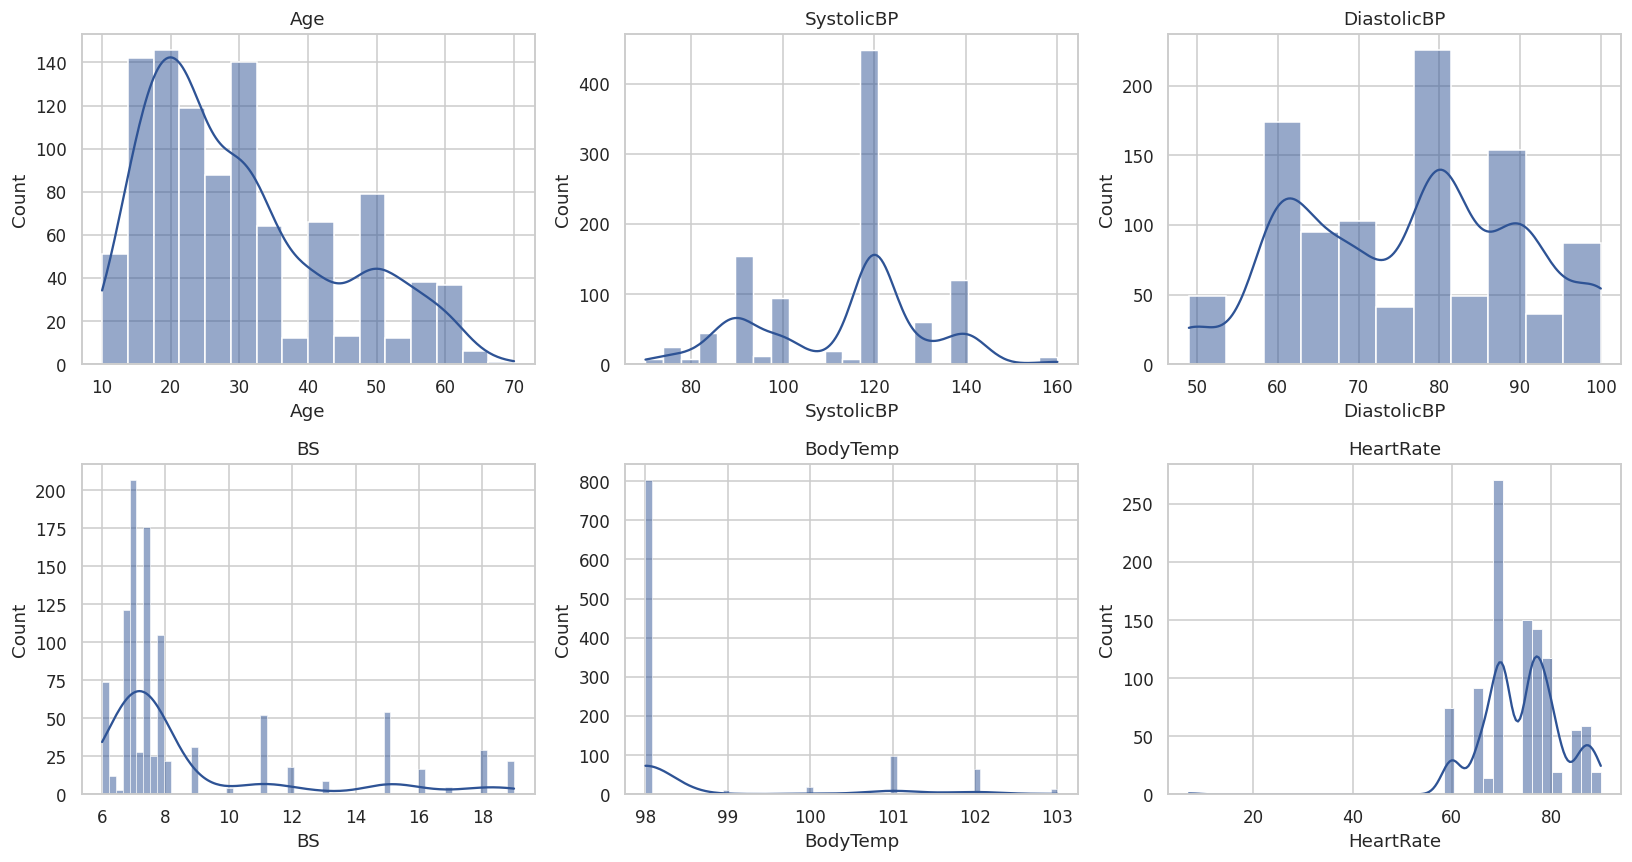

In [8]:
variables_numericas = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), variables_numericas):
    sns.histplot(df[col], kde=True, ax=ax, color="#2E5395")
    ax.set_title(col)
plt.tight_layout()
plt.show()


### 3.2 Distribución de las variables clínicas por nivel de riesgo (diagramas de caja)

/tmp/ipykernel_198/1723987654.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="RiskLevel", y=col, ax=ax, order=orden_riesgo, palette=paleta)
/tmp/ipykernel_198/1723987654.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="RiskLevel", y=col, ax=ax, order=orden_riesgo, palette=paleta)
/tmp/ipykernel_198/1723987654.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="RiskLevel", y=col, ax=ax, order=orden_riesgo, palette=paleta)
/tmp/ipykernel_198/1723987654.py:4: FutureWarning: 

Passing `palette` without 

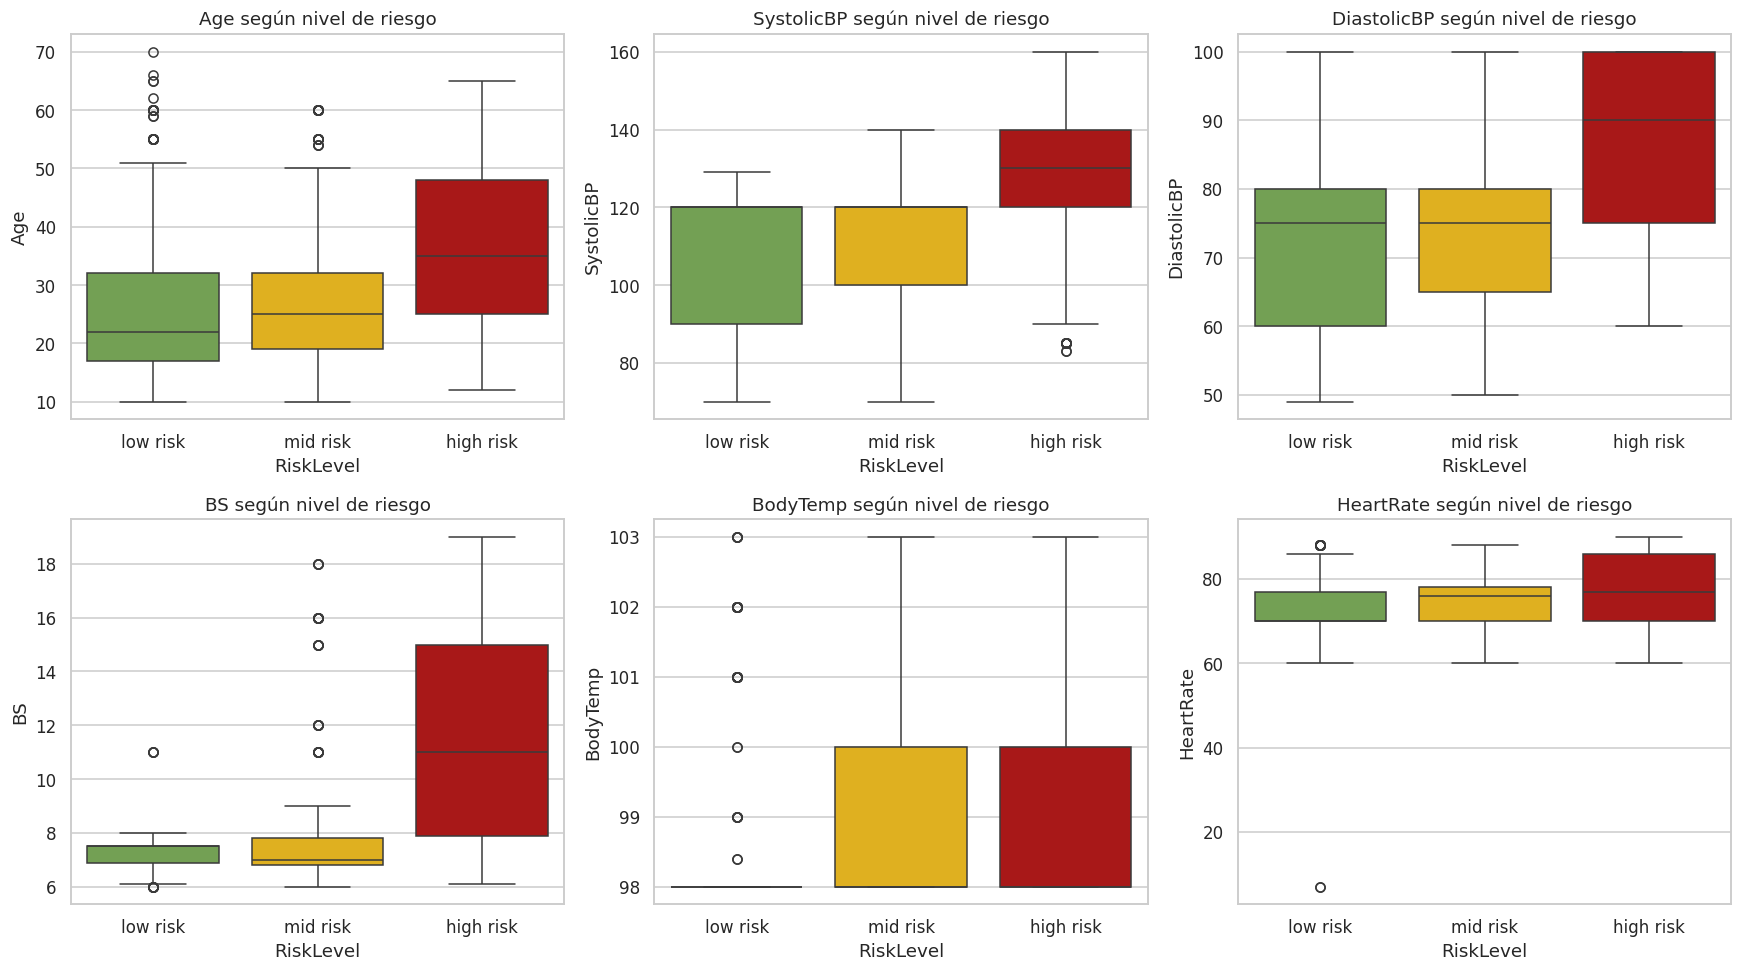

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
paleta = {"low risk": "#70AD47", "mid risk": "#FFC000", "high risk": "#C00000"}
for ax, col in zip(axes.flatten(), variables_numericas):
    sns.boxplot(data=df, x="RiskLevel", y=col, ax=ax, order=orden_riesgo, palette=paleta)
    ax.set_title(f"{col} según nivel de riesgo")
plt.tight_layout()
plt.show()


### 3.3 Matriz de correlación entre variables numéricas

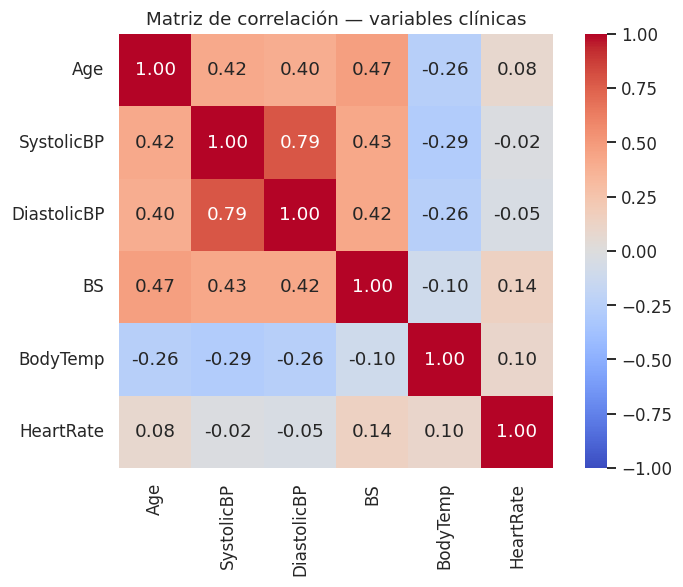

In [10]:
plt.figure(figsize=(7, 5.5))
corr = df[variables_numericas].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación — variables clínicas")
plt.tight_layout()
plt.show()


### 3.4 Distribución de la variable objetivo (`RiskLevel`)

/tmp/ipykernel_198/944636748.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=conteo.index, y=conteo.values, order=orden_riesgo, palette=paleta)


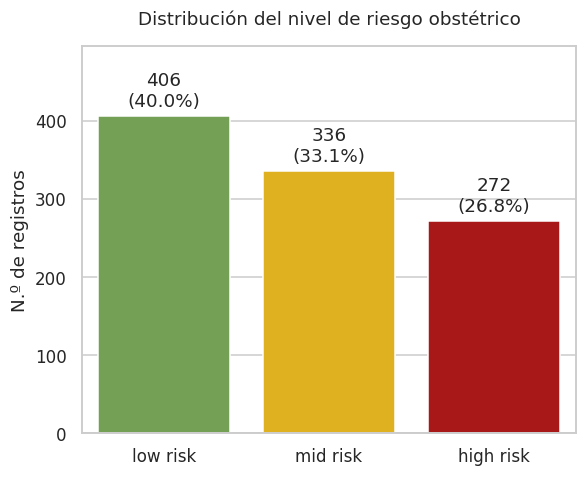

In [11]:
plt.figure(figsize=(5.5, 4.5))
conteo = df["RiskLevel"].value_counts().reindex(orden_riesgo)
ax = sns.barplot(x=conteo.index, y=conteo.values, order=orden_riesgo, palette=paleta)
ax.set_ylim(0, conteo.max() * 1.22)
for i, v in enumerate(conteo.values):
    ax.text(i, v + conteo.max() * 0.03, f"{v}\n({v/len(df)*100:.1f}%)", ha="center")
plt.title("Distribución del nivel de riesgo obstétrico", pad=14)
plt.ylabel("N.º de registros")
plt.xlabel("")
plt.tight_layout()
plt.show()


### 3.5 Relación entre edad, glucosa y nivel de riesgo

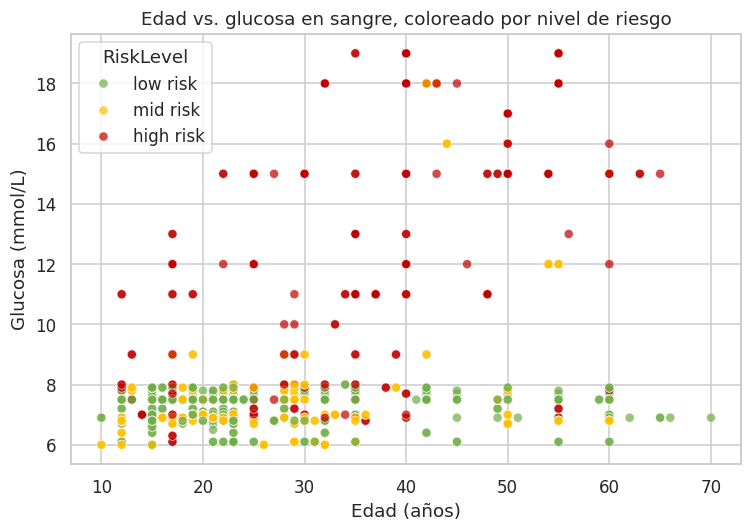

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="BS", hue="RiskLevel", hue_order=orden_riesgo,
                 palette=paleta, alpha=0.7)
plt.title("Edad vs. glucosa en sangre, coloreado por nivel de riesgo")
plt.xlabel("Edad (años)")
plt.ylabel("Glucosa (mmol/L)")
plt.tight_layout()
plt.show()


## 4. Identificación de problemas de calidad de datos

### 4.1 Valores nulos


In [13]:
nulos = df.isnull().sum()
porcentaje_nulos = (nulos / len(df) * 100).round(2)
pd.DataFrame({"nulos": nulos, "% nulos": porcentaje_nulos})


,nulos,% nulos
Age,0,0.0
SystolicBP,0,0.0
DiastolicBP,0,0.0
BS,0,0.0
BodyTemp,0,0.0
HeartRate,0,0.0
RiskLevel,0,0.0


### 4.2 Registros duplicados

In [14]:
n_duplicados = df.duplicated().sum()
print(f"Registros duplicados: {n_duplicados} ({n_duplicados/len(df)*100:.1f}% del total)")


Registros duplicados: 562 (55.4% del total)


### 4.3 Valores atípicos (outliers)

Se identifican con el criterio del rango intercuartílico (IQR): un valor se considera atípico si está por
debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. También se revisan los rangos fisiológicamente
plausibles de cada variable, ya que un outlier estadístico no siempre es un error de captura.


In [15]:
def resumen_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = serie[(serie < lim_inf) | (serie > lim_sup)]
    return len(atipicos), round(lim_inf, 2), round(lim_sup, 2)

resumen = []
for col in variables_numericas:
    n_atip, lim_inf, lim_sup = resumen_outliers_iqr(df[col])
    resumen.append({
        "variable": col,
        "n_outliers_IQR": n_atip,
        "% outliers": round(n_atip / len(df) * 100, 2),
        "límite_inferior": lim_inf,
        "límite_superior": lim_sup,
        "mínimo_observado": df[col].min(),
        "máximo_observado": df[col].max(),
    })
pd.DataFrame(resumen)


,variable,n_outliers_IQR,% outliers,límite_inferior,límite_superior,mínimo_observado,máximo_observado
0,Age,1,0.10,-11.00,69.00,10.0,70.0
1,SystolicBP,10,0.99,70.00,150.00,70.0,160.0
2,DiastolicBP,0,0.00,27.50,127.50,49.0,100.0
3,BS,210,20.71,5.25,9.65,6.0,19.0
4,BodyTemp,210,20.71,98.00,98.00,98.0,103.0
5,HeartRate,2,0.20,55.00,95.00,7.0,90.0


### 4.4 Desbalance de clases

Se calcula la proporción de cada categoría de la variable objetivo. Un desbalance relevante (por ejemplo,
una diferencia mayor al 15-20 % entre la clase mayoritaria y la minoritaria) debe tenerse en cuenta al
entrenar los modelos de clasificación en la Fase 2, evaluando estrategias como el sobremuestreo (SMOTE),
el submuestreo o el ajuste de pesos por clase.


In [16]:
proporciones = (df["RiskLevel"].value_counts(normalize=True).reindex(orden_riesgo) * 100).round(1)
print("Proporción de cada clase de riesgo:")
print(proporciones.astype(str) + " %")

diferencia = proporciones.max() - proporciones.min()
print(f"\nDiferencia entre la clase mayoritaria y la minoritaria: {diferencia:.1f} puntos porcentuales")


Proporción de cada clase de riesgo:
RiskLevel
low risk     40.0 %
mid risk     33.1 %
high risk    26.8 %
Name: proportion, dtype: str

Diferencia entre la clase mayoritaria y la minoritaria: 13.2 puntos porcentuales


## 5. Conclusiones del análisis exploratorio

El conjunto de datos Maternal Health Risk no presenta valores nulos ni un número relevante de registros
duplicados, por lo que su calidad estructural es adecuada para avanzar a la fase de modelado. Sin embargo,
el análisis por rango intercuartílico identifica valores atípicos en variables como la glucosa y la frecuencia
cardiaca, varios de los cuales corresponden a gestantes con complicaciones reales (por ejemplo, niveles de
glucosa asociados a diabetes gestacional) y no a errores de captura, por lo que no deberían eliminarse sin
antes contrastarlos con criterio clínico. La glucosa y la edad muestran, además, la asociación más clara con
el nivel de riesgo: los diagramas de caja y el gráfico de dispersión evidencian que las gestantes clasificadas
como riesgo alto tienden a concentrarse en edades más avanzadas y niveles de glucosa más elevados, lo cual
es consistente con lo reportado en la literatura revisada en el estado del arte.

En cuanto al balance de clases, la distribución de `RiskLevel` no es uniforme entre las tres categorías, lo que
confirma la necesidad —ya anticipada en el documento de propuesta— de aplicar una estrategia de balanceo
antes de entrenar los modelos de clasificación en la Fase 2, de modo que el sistema no subestime
sistemáticamente el riesgo alto, que es precisamente el caso donde una alerta temprana es más crítica. Estos
hallazgos, junto con los rangos clínicos observados en este dataset público, servirán como referencia para
calibrar la generación del conjunto de datos simulado de controles prenatales en zonas rurales del Cesar y
La Guajira.
